# Results and graphs from experiment exports

This notebook reads `accelerator-results.json` from notebook 03 and
`mnist-results.json` from notebook 05. Plot values and numerical observations
come from those files; this notebook does not rerun training or simulations.

For a fresh experiment, run notebooks 03 and 05 and keep their downloaded JSON
files. In Colab, choose **Runtime → Run all** here, then select both exports in
the upload prompt. Renamed browser downloads are accepted by their contents.
Locally, place the files beside this notebook or in `results/` at the repository
root. A full checkout finds the checked [timing export](../results/accelerator-results.json)
and [MNIST export](../results/mnist-results.json) automatically.

Timing covers matrix calculations and transfers only. Bias, activation,
rescaling, and choosing a digit are excluded. Matrix-stage rates describe an
image's two matrix products, not a complete prediction per second.


In [1]:
import copy
import json
from pathlib import Path
import sys
import tempfile
import unittest
import matplotlib.pyplot as plt


def load_exports(roots=None, upload=None):
    roots = [Path("."), Path("results"), Path("../results")] if roots is None else roots
    names = {"accelerator": "accelerator-results.json", "mnist": "mnist-results.json"}
    exports = {}
    for kind, name in names.items():
        for root in roots:
            candidate = Path(root) / name
            if candidate.is_file():
                exports[kind] = json.loads(candidate.read_text())
                print("Loaded", candidate)
                break
    missing = set(names) - exports.keys()
    if missing:
        if upload is None:
            try:
                from google.colab import files
            except ImportError:
                raise FileNotFoundError("Place accelerator-results.json and mnist-results.json "
                                        "beside this notebook or in results/, then Run all.") from None
            upload = files.upload
        print("Select the missing exports:", ", ".join(names[k] for k in sorted(missing)))
        for name, payload in upload().items():
            data = json.loads(payload)
            kind = data.get("kind")
            if kind in missing:
                exports[kind] = data
                print("Loaded uploaded", name)
        if set(names) - exports.keys():
            raise ValueError("Both timing and MNIST exports are required; rerun this cell and select both.")
    return exports["accelerator"], exports["mnist"]


def require(condition, message):
    if not condition:
        raise ValueError(message)


def positive_int(value):
    return type(value) is int and value > 0


def make_plot_data(accelerator, mnist):
    for data, kind in [(accelerator, "accelerator"), (mnist, "mnist")]:
        require(data.get("kind") == kind and data.get("schema_version") == 1,
                "Wrong export type or unsupported schema version; regenerate the exports.")
    require(accelerator["network_dimensions"] == mnist["network_dimensions"], "Network dimensions differ.")
    verification = mnist["verification"]
    require(accelerator["timing_scope"] == verification["timing_scope"] == "matrix_stages_only",
            "The graph requires matching matrix-stage timing scopes.")
    clock = accelerator["clock_hz"]
    require(positive_int(clock) and clock == verification["clock_hz"], "Clock assumptions differ.")
    config = accelerator["base_config"]
    require(all(positive_int(v) for v in config.values()) and config == verification["config"],
            "Baseline hardware settings differ; regenerate exports with matching settings.")
    accuracy = mnist["accuracy"]
    count = accuracy["test_images"]
    require(positive_int(count), "Test image count must be positive.")
    for key in ("fp32_correct", "int8_correct"):
        require(type(accuracy[key]) is int and 0 <= accuracy[key] <= count, "Invalid accuracy counts.")
    require(type(accuracy["fp32_int8_disagreements"]) is int
            and abs(accuracy["fp32_correct"] - accuracy["int8_correct"])
            <= accuracy["fp32_int8_disagreements"] <= count, "Invalid prediction-disagreement count.")
    baseline = {}
    for precision in ("fp32", "int8"):
        layers = accelerator["baseline_layers"][precision]
        require(len(layers) == len(accelerator["network_dimensions"]) - 1, "Missing baseline layers.")
        for i, layer in enumerate(layers):
            require((layer["rows"], layer["inner"], layer["columns"]) ==
                    (1, *accelerator["network_dimensions"][i:i+2]), "Baseline dimensions differ.")
            phases = [layer[k + "_cycles"] for k in ("load_inputs", "load_weights", "compute", "store_outputs")]
            require(all(positive_int(v) for v in phases)
                    and sum(phases) == layer["total_cycles"], "Invalid baseline cycle accounting.")
        baseline[precision] = sum(layer["total_cycles"] for layer in layers)
    require(bool(verification["rows"]), "Real-value verification rows are missing.")
    for row in verification["rows"]:
        require(all(row[p + "_cycles"] == baseline[p] for p in baseline),
                "Real-value verification cycles disagree with the baseline.")
    sweeps = {}
    for key, varying in [("lane_sweep", "lanes"), ("external_bandwidth_sweep", "external_bytes_per_cycle")]:
        rows = sorted(accelerator[key], key=lambda row: row["config"][varying])
        require(bool(rows), "Sweep results are missing.")
        values = [row["config"][varying] for row in rows]
        require(len(values) == len(set(values)), "Duplicate sweep settings.")
        reference_config = rows[0]["config"]
        for row in rows:
            require(all(positive_int(v) for v in row["config"].values()), "Invalid sweep hardware settings.")
            require(all(row["config"][k] == reference_config[k] for k in config if k != varying),
                    "A sweep changes more than its named hardware parameter.")
            require(all(positive_int(row[p + "_cycles"]) for p in baseline), "Invalid sweep cycle count.")
            if row["config"] == config:
                require(all(row[p + "_cycles"] == baseline[p] for p in baseline),
                        "Sweep and baseline cycles disagree.")
        sweeps[key] = rows
    return {"accuracy": [100 * accuracy[p + "_correct"] / count for p in ("fp32", "int8")],
            "test_images": count, "disagreements": accuracy["fp32_int8_disagreements"],
            "latency_us": [baseline[p] / clock * 1e6 for p in ("fp32", "int8")],
            "speedup": baseline["fp32"] / baseline["int8"], "clock_hz": clock,
            "base_config": config, "lane_rows": sweeps["lane_sweep"],
            "bandwidth_rows": sweeps["external_bandwidth_sweep"]}


accelerator_results, mnist_results = load_exports()
plot_data = make_plot_data(accelerator_results, mnist_results)
print("Exports match in network dimensions, hardware settings, clock, and baseline cycles.")
print("Training settings:", mnist_results["training_settings"])
print("FP32 parameter fingerprint:", mnist_results["fp32_parameter_sha256"])


Loaded results/accelerator-results.json
Loaded results/mnist-results.json
Exports match in network dimensions, hardware settings, clock, and baseline cycles.
Training settings: {'epochs': 8, 'hidden_units': 64, 'batch_size': 128, 'learning_rate': 0.001, 'seed': 530}
FP32 parameter fingerprint: 5766aca29a3e6af0a0a6f3710f5201e6ce34d29defd498d85b9c2c5e91790566


## 1. FP32 vs INT8 accuracy

Percentages are calculated from exported correct counts and test-set size.
INT8 refers to the integer path, using separately calibrated scales.


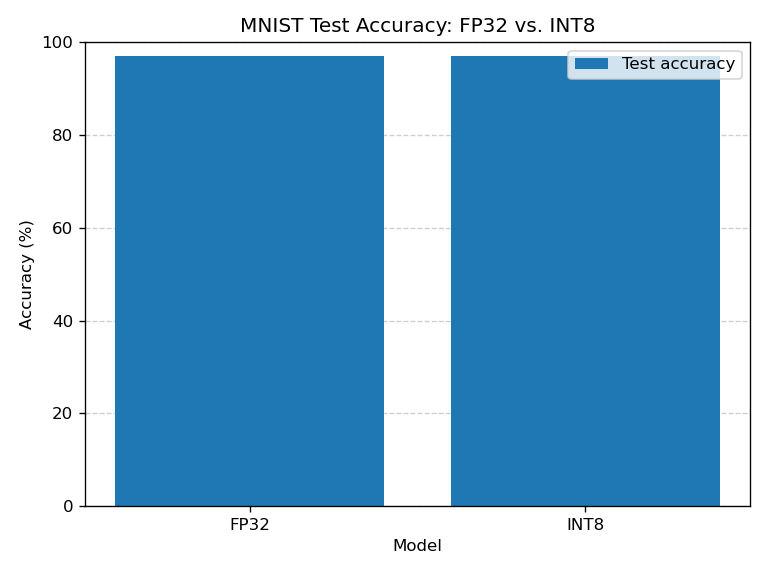

In [2]:
import matplotlib.pyplot as plt

models = ["FP32", "INT8"]
accuracy = plot_data["accuracy"]

fig, ax = plt.subplots()
ax.bar(models, accuracy, label="Test accuracy")
ax.set_title("MNIST Test Accuracy: FP32 vs. INT8")
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
ax.legend()
fig.tight_layout()
plt.show()


In [3]:
fp_accuracy, int_accuracy = plot_data["accuracy"]
print(f"FP32: {fp_accuracy:.2f}%; integer INT8: {int_accuracy:.2f}%.")
print(f"INT8 minus FP32: {int_accuracy - fp_accuracy:+.2f} percentage points; "
      f"{plot_data['disagreements']:,} different predictions out of {plot_data['test_images']:,}.")
print("This result describes this model and run; a small increase does not establish INT8 as inherently more accurate.")


FP32: 96.96%; integer INT8: 96.98%.
INT8 minus FP32: +0.02 percentage points; 15 different predictions out of 10,000.
This result describes this model and run; a small increase does not establish INT8 as inherently more accurate.


## 2. FP32 vs INT8 matrix-stage latency

Sum the exported baseline layer cycles and divide by the exported clock.
Other prediction operations remain outside the timing model.


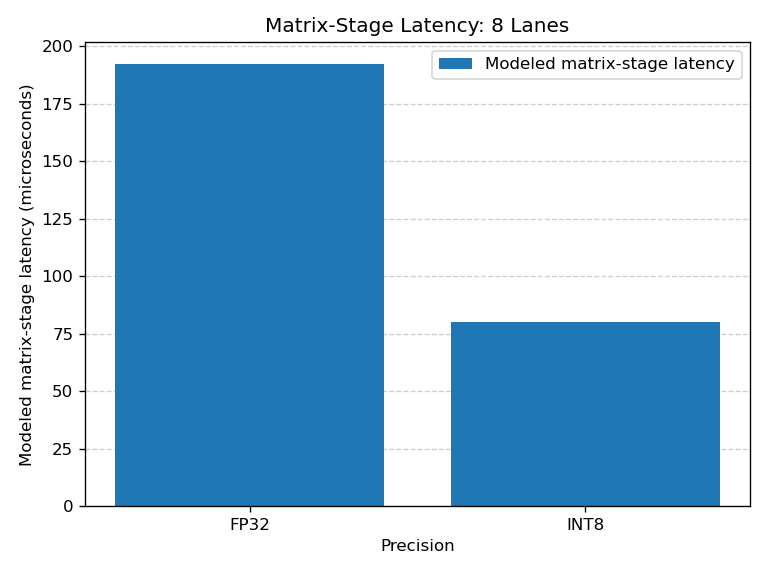

In [4]:
import matplotlib.pyplot as plt

precisions = ["FP32", "INT8"]
latency_us = plot_data["latency_us"]

fig, ax = plt.subplots()
ax.bar(precisions, latency_us, label="Modeled matrix-stage latency")
ax.set_title(f"Matrix-Stage Latency: {plot_data['base_config']['lanes']} Lanes")
ax.set_xlabel("Precision")
ax.set_ylabel("Modeled matrix-stage latency (microseconds)")
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
ax.legend()
fig.tight_layout()
plt.show()


In [5]:
print(f"Matrix-stage time: FP32 {plot_data['latency_us'][0]:.2f} microseconds; "
      f"INT8 {plot_data['latency_us'][1]:.2f} microseconds.")
print(f"Modeled speedup: {plot_data['speedup']:.3f}x at {plot_data['clock_hz'] / 1e6:g} MHz.")
print("These are matrix-stage estimates, not complete inference times or physical measurements.")


Matrix-stage time: FP32 192.04 microseconds; INT8 80.25 microseconds.
Modeled speedup: 2.393x at 100 MHz.
These are matrix-stage estimates, not complete inference times or physical measurements.


## 3. Matrix-stage rate vs lanes

Each point is the exported clock divided by the measured cycle count for that
sweep case. Other hardware parameters stay fixed within the sweep.


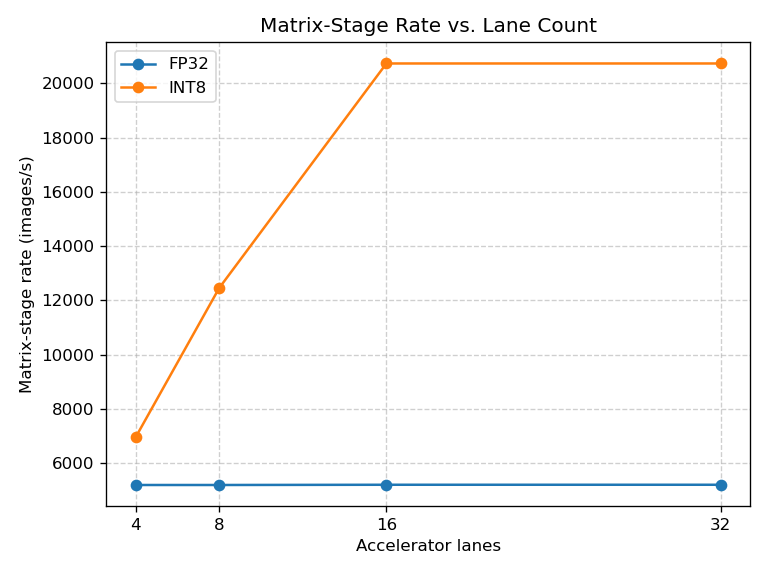

In [6]:
import matplotlib.pyplot as plt

lane_rows = plot_data["lane_rows"]
lanes = [row["config"]["lanes"] for row in lane_rows]
fp32_throughput = [plot_data["clock_hz"] / row["fp32_cycles"] for row in lane_rows]
int8_throughput = [plot_data["clock_hz"] / row["int8_cycles"] for row in lane_rows]

fig, ax = plt.subplots()
ax.plot(lanes, fp32_throughput, marker="o", label="FP32")
ax.plot(lanes, int8_throughput, marker="o", label="INT8")
ax.set_title("Matrix-Stage Rate vs. Lane Count")
ax.set_xlabel("Accelerator lanes")
ax.set_ylabel("Matrix-stage rate (images/s)")
ax.set_xticks(lanes)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend()
fig.tight_layout()
plt.show()


In [7]:
local_read_bytes = lane_rows[0]["config"]["local_read_bytes_per_cycle"]
print(f"Local reads allow at most {local_read_bytes // 2} INT8 or {local_read_bytes // 8} FP32 MACs/cycle.")
for row, fp_rate, int_rate in zip(lane_rows, fp32_throughput, int8_throughput):
    print(f"{row['config']['lanes']} lanes: FP32 {fp_rate:,.2f}; INT8 {int_rate:,.2f} matrix-stage images/s.")
if len(lane_rows) > 1 and lane_rows[-1]["int8_cycles"] == lane_rows[-2]["int8_cycles"]:
    print("The last two INT8 lane cases have equal cycle counts; more lanes alone did not help.")


Local reads allow at most 16 INT8 or 4 FP32 MACs/cycle.
4 lanes: FP32 5,207.25; INT8 6,963.30 matrix-stage images/s.
8 lanes: FP32 5,207.25; INT8 12,461.06 matrix-stage images/s.
16 lanes: FP32 5,215.94; INT8 20,725.39 matrix-stage images/s.
32 lanes: FP32 5,215.94; INT8 20,725.39 matrix-stage images/s.
The last two INT8 lane cases have equal cycle counts; more lanes alone did not help.


## 4. INT8 matrix-stage rate vs external bandwidth

Read the external-bandwidth cases from the export. Faster transfers can shorten
loading and storing while the separate local operand-read limit stays fixed.


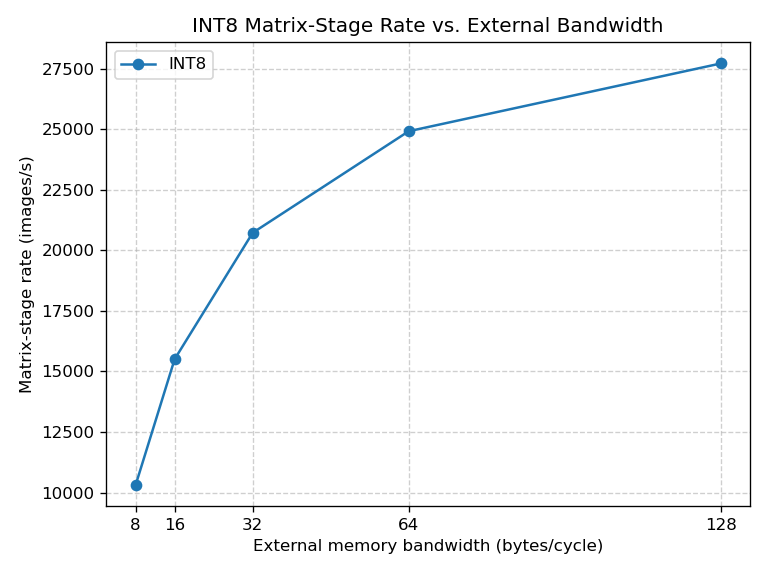

In [8]:
import matplotlib.pyplot as plt

bandwidth_rows = plot_data["bandwidth_rows"]
bandwidth = [row["config"]["external_bytes_per_cycle"] for row in bandwidth_rows]
int8_throughput = [plot_data["clock_hz"] / row["int8_cycles"] for row in bandwidth_rows]

fig, ax = plt.subplots()
ax.plot(bandwidth, int8_throughput, marker="o", label="INT8")
ax.set_title("INT8 Matrix-Stage Rate vs. External Bandwidth")
ax.set_xlabel("External memory bandwidth (bytes/cycle)")
ax.set_ylabel("Matrix-stage rate (images/s)")
ax.set_xticks(bandwidth)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend()
fig.tight_layout()
plt.show()


In [9]:
for row, rate in zip(bandwidth_rows, int8_throughput):
    print(f"{row['config']['external_bytes_per_cycle']} external bytes/cycle: {rate:,.2f} matrix-stage images/s.")
print("This sweep changes transfer costs, not the fixed local read budget during compute.")


8 external bytes/cycle: 10,314.60 matrix-stage images/s.
16 external bytes/cycle: 15,508.68 matrix-stage images/s.
32 external bytes/cycle: 20,725.39 matrix-stage images/s.
64 external bytes/cycle: 24,919.01 matrix-stage images/s.
128 external bytes/cycle: 27,716.19 matrix-stage images/s.
This sweep changes transfer costs, not the fixed local read budget during compute.


## Check the graph inputs

Checks reject incompatible exports and invalid counts/cycles. They also verify
that changing an input count changes the plot data, and that upload loading
accepts browser-renamed files. The upload callback test does not exercise the
Colab browser interface itself.


In [10]:
class ResultInputTests(unittest.TestCase):
    def test_changed_counts_change_plot_data(self):
        changed = copy.deepcopy(mnist_results)
        changed["accuracy"].update(fp32_correct=7500, int8_correct=6500,
                                   test_images=10000, fp32_int8_disagreements=2000)
        self.assertEqual(make_plot_data(accelerator_results, changed)["accuracy"], [75.0, 65.0])

    def test_incompatible_exports_are_rejected(self):
        for key, value in [("clock_hz", 1), ("network_dimensions", [1, 2, 3]), ("schema_version", 99)]:
            changed = copy.deepcopy(accelerator_results)
            changed[key] = value
            with self.subTest(key=key), self.assertRaises(ValueError):
                make_plot_data(changed, mnist_results)

    def test_invalid_counts_and_cycles_are_rejected(self):
        changed = copy.deepcopy(mnist_results)
        changed["accuracy"]["int8_correct"] = changed["accuracy"]["test_images"] + 1
        with self.assertRaises(ValueError):
            make_plot_data(accelerator_results, changed)
        changed = copy.deepcopy(accelerator_results)
        changed["lane_sweep"][0]["int8_cycles"] = 0
        with self.assertRaises(ValueError):
            make_plot_data(changed, mnist_results)

    def test_renamed_uploads_are_loaded_by_contents(self):
        uploaded = {"accelerator-results (1).json": json.dumps(accelerator_results).encode(),
                    "mnist-results (2).json": json.dumps(mnist_results).encode()}
        with tempfile.TemporaryDirectory() as root:
            a, m = load_exports(roots=[Path(root)], upload=lambda: uploaded)
        self.assertEqual(make_plot_data(a, m), plot_data)

    def test_missing_upload_is_reported(self):
        with tempfile.TemporaryDirectory() as root, self.assertRaises(ValueError):
            load_exports(roots=[Path(root)], upload=lambda: {})

result = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(
    unittest.defaultTestLoader.loadTestsFromTestCase(ResultInputTests)
)
if not result.wasSuccessful():
    raise AssertionError("An export or graph-input check failed.")
print(f"All {result.testsRun} result-input checks passed.")


test_changed_counts_change_plot_data (__main__.ResultInputTests.test_changed_counts_change_plot_data) ... ok
test_incompatible_exports_are_rejected (__main__.ResultInputTests.test_incompatible_exports_are_rejected) ... ok
test_invalid_counts_and_cycles_are_rejected (__main__.ResultInputTests.test_invalid_counts_and_cycles_are_rejected) ... ok
test_missing_upload_is_reported (__main__.ResultInputTests.test_missing_upload_is_reported) ... Select the missing exports: accelerator-results.json, mnist-results.json
ok
test_renamed_uploads_are_loaded_by_contents (__main__.ResultInputTests.test_renamed_uploads_are_loaded_by_contents) ... Select the missing exports: accelerator-results.json, mnist-results.json
Loaded uploaded accelerator-results (1).json
Loaded uploaded mnist-results (2).json
ok

----------------------------------------------------------------------
Ran 5 tests in 0.002s

OK
All 5 result-input checks passed.
